# Offline navigation: BC, TD3 and BCQ

This notebook follows one real transition from `data/mixed.npz` through a BCQ update.
The saved outputs were computed on CPU.

## 1. Google Colab setup

Run the next cell in Colab to clone the project and install dependencies.
For local execution, start Jupyter in the project directory.

In [1]:
from importlib.util import find_spec
import os
from pathlib import Path
import subprocess
import sys

if find_spec("google") is not None and find_spec("google.colab") is not None:
    project = Path("/content/RL_Project")
    if not project.exists():
        subprocess.run([
            "git", "clone", "https://github.com/Andreyfdp/RL_Project.git", str(project)
        ], check=True)
    os.chdir(project)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from IPython.display import Image, Markdown, display

from bcq import BCQ
from dataset import OfflineDataset
from train import set_seed

torch.set_num_threads(1)
set_seed(0)
dataset = OfflineDataset("data/mixed.npz", device="cpu")
print("Transitions:", len(dataset))
print("PyTorch:", torch.__version__, "CUDA:", torch.cuda.is_available())

Transitions: 24598
PyTorch: 2.6.0+cu126 CUDA: True


## 2. One real transition

The state is `[x, y, goal_x - x, goal_y - y]`.
`done` marks a goal or collision. Time limits are stored separately in `timeouts`
and keep the Bellman bootstrap. This example updates one transition; training uses batch=256.

In [3]:
index = 0
batch = tuple(t[index:index + 1].clone() for t in (
    dataset.states, dataset.actions, dataset.rewards, dataset.next_states, dataset.dones
))
states, actions, rewards, next_states, dones = batch
agent = BCQ(4, 2, phi=0.05, device="cpu")
print("Dataset index:", index)
for name, value in zip(("s", "a", "r", "s_next", "done"), batch):
    print(name, "=", value.numpy().round(5))
with np.load("data/mixed.npz") as raw:
    print("timeout =", raw["timeouts"][index] if "timeouts" in raw else "not provided")

Dataset index: 0
s = [[1.16437 0.96333 7.83563 8.03667]]
a = [[0.3861  0.94114]]
r = [[1.62687]]
s_next = [[1.29951 1.29273 7.70049 7.70727]]
done = [[0.]]
timeout = [0.]


## 3. VAE: encode, sample, decode and update

$z=\mu+\sigma\epsilon$, $L_{VAE}=MSE(\hat a,a)+0.5 KL$.
Use the same $\epsilon$ and latent probe before and after the update to isolate
parameter changes from sampling noise.

In [4]:
epsilon = torch.randn(1, agent.vae.latent_dim)
probe_z = torch.randn_like(epsilon).clamp(-0.5, 0.5)
mean, log_std = agent.vae.encode(states, actions)
std = log_std.exp()
reconstructed = agent.vae.decode(states, mean + std * epsilon)
reconstruction_loss = F.mse_loss(reconstructed, actions)
kl = -0.5 * torch.mean(1 + torch.log(std.square() + 1e-8) - mean.square() - std.square())
vae_loss = reconstruction_loss + 0.5 * kl
reconstruction_before = reconstructed.detach().clone()
with torch.no_grad():
    candidate_before = agent.vae.decode(states, probe_z)
agent.vae_optimizer.zero_grad()
vae_loss.backward()
agent.vae_optimizer.step()
with torch.no_grad():
    mean_after, log_std_after = agent.vae.encode(states, actions)
    reconstruction_after = agent.vae.decode(states, mean_after + log_std_after.exp() * epsilon)
    candidate = agent.vae.decode(states, probe_z)
print("mu:", mean.detach().numpy().round(5), "std:", std.detach().numpy().round(5))
print(f"reconstruction loss={reconstruction_loss.item():.6f}; KL={kl.item():.6f}; total={vae_loss.item():.6f}")
print("Real action:", actions.numpy().round(5))
print("Reconstruction before:", reconstruction_before.numpy().round(5))
print("Reconstruction after: ", reconstruction_after.numpy().round(5))
print("Fixed latent candidate before/after:", candidate_before.numpy(), candidate.numpy())

mu: [[ 0.2404  -0.74124  0.32712 -0.08393]] std: [[0.58075 0.57863 0.81997 0.45805]]
reconstruction loss=1.192704; KL=0.301888; total=1.343648
Real action: [[0.3861  0.94114]]
Reconstruction before: [[-0.38442 -0.39741]]
Reconstruction after:  [[0.21733 0.51078]]
Fixed latent candidate before/after: [[-0.23907794 -0.40425003]] [[0.38322434 0.46909338]]


## 4. Perturbation and twin Q estimates

$\tilde a=clip(a_{VAE}+\Phi\tanh(\xi(s,a_{VAE})), -1,1)$.
Each action correction is bounded by Phi=0.05. Both critics then score the action.

In [5]:
with torch.no_grad():
    perturbed_before = agent.actor(states, candidate)
    candidate_q1, candidate_q2 = agent.critic(states, perturbed_before)
print("VAE action:", candidate.numpy().round(5))
print("Perturbed action:", perturbed_before.numpy().round(5))
print("Correction:", (perturbed_before - candidate).numpy().round(5))
print("Q1, Q2:", candidate_q1.item(), candidate_q2.item())

VAE action: [[0.38322 0.46909]]
Perturbed action: [[0.37091 0.44387]]
Correction: [[-0.01232 -0.02523]]
Q1, Q2: -0.020635254681110382 -0.9000071883201599


## 5. Target y from ten next-state candidates

$Q_{mix}=0.75\min(Q_1',Q_2')+0.25\max(Q_1',Q_2')$,
$y=r+\gamma(1-done)\max_i Q_{mix}(s',a_i')$.
Compute the target without gradients after the VAE update, as in `BCQ.train`.

In [6]:
with torch.no_grad():
    repeated_next = next_states.repeat_interleave(10, dim=0)
    next_candidates = agent.vae.decode(repeated_next)
    next_actions = agent.actor_target(repeated_next, next_candidates)
    target_q1, target_q2 = agent.critic_target(repeated_next, next_actions)
    mixed_q = 0.75 * torch.minimum(target_q1, target_q2) + 0.25 * torch.maximum(target_q1, target_q2)
    best_q = mixed_q.view(1, 10).max(dim=1, keepdim=True).values
    target_y = rewards + (1 - dones) * agent.gamma * best_q
print("i      VAE a                   perturbed a               Q1        Q2       Qmix")
for i in range(10):
    print(f"{i}  {next_candidates[i].numpy().round(4)}  {next_actions[i].numpy().round(4)}  "
          f"{target_q1[i].item():9.5f} {target_q2[i].item():9.5f} {mixed_q[i].item():9.5f}")
print(f"y = {rewards.item():.6f} + {agent.gamma} * (1 - {dones.item():.0f}) * {best_q.item():.6f} = {target_y.item():.6f}")

i      VAE a                   perturbed a               Q1        Q2       Qmix
0  [0.3562 0.4338]  [0.3436 0.4089]   -0.01757  -0.89125  -0.67283
1  [0.3808 0.4584]  [0.3683 0.4334]   -0.01546  -0.89012  -0.67145
2  [0.3119 0.4471]  [0.2993 0.422 ]   -0.01763  -0.89559  -0.67610
3  [0.3364 0.4586]  [0.3238 0.4335]   -0.01648  -0.89394  -0.67458
4  [0.3507 0.4364]  [0.3381 0.4115]   -0.01754  -0.89183  -0.67325
5  [0.3164 0.4748]  [0.3038 0.4497]   -0.01588  -0.89631  -0.67621
6  [0.3125 0.4875]  [0.2998 0.4624]   -0.01517  -0.89717  -0.67667
7  [0.3167 0.4823]  [0.3041 0.4572]   -0.01542  -0.89659  -0.67630
8  [0.3072 0.4369]  [0.2946 0.4119]   -0.01832  -0.89558  -0.67626
9  [0.368  0.4334]  [0.3555 0.4084]   -0.01733  -0.89022  -0.67200
y = 1.626872 + 0.99 * (1 - 0) * -0.671455 = 0.962131


## 6. Critic update: before and after

Minimize $(Q_1(s,a)-y)^2+(Q_2(s,a)-y)^2$ on the **dataset action**.
Compare both critics against the same fixed target after the update.

In [7]:
current_q1, current_q2 = agent.critic(states, actions)
critic_loss = F.mse_loss(current_q1, target_y) + F.mse_loss(current_q2, target_y)
q_before = [current_q1.item(), current_q2.item()]
agent.critic_optimizer.zero_grad()
critic_loss.backward()
agent.critic_optimizer.step()
with torch.no_grad():
    after_q1, after_q2 = agent.critic(states, actions)
    critic_loss_after = F.mse_loss(after_q1, target_y) + F.mse_loss(after_q2, target_y)
q_after = [after_q1.item(), after_q2.item()]
print("Target y:", target_y.item())
print("Q1, Q2 before:", q_before)
print("Q1, Q2 after: ", q_after)
print("Critic loss before / after:", critic_loss.item(), critic_loss_after.item())

Target y: 0.9621313214302063
Q1, Q2 before: [0.011175818741321564, -0.9041357636451721]
Q1, Q2 after:  [1.231535792350769, 0.29520493745803833]
Critic loss before / after: 4.387269020080566 0.5173695683479309


## 7. Actor and target updates: before and after

$L_{actor}=-Q_1(s,\xi(s,a_{VAE}))$. Detach the VAE candidate from its computation graph.
Compare the same candidate before and after the actor step using the updated critic.
One Adam step does not guarantee that every individual Q estimate improves.

Action before: [[0.370906 0.443866]]
Action after:  [[0.400027 0.491534]]
Q1 before / after actor step: 1.1804640293121338 1.1861424446105957
Actor loss before / after: -1.1804640293121338 -1.1861424446105957
Soft update tau: 0.005


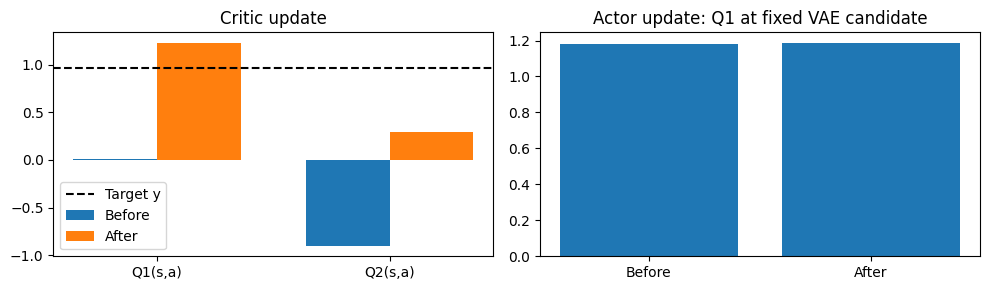

In [8]:
fixed_candidate = candidate.detach()
before_action = agent.actor(states, fixed_candidate)
actor_q_before = agent.critic.q1(states, before_action)
actor_loss = -actor_q_before.mean()
agent.actor_optimizer.zero_grad()
actor_loss.backward()
agent.actor_optimizer.step()
with torch.no_grad():
    after_action = agent.actor(states, fixed_candidate)
    actor_q_after = agent.critic.q1(states, after_action)
agent._soft_update(agent.critic, agent.critic_target)
agent._soft_update(agent.actor, agent.actor_target)
print("Action before:", before_action.detach().numpy().round(6))
print("Action after: ", after_action.numpy().round(6))
print("Q1 before / after actor step:", actor_q_before.item(), actor_q_after.item())
print("Actor loss before / after:", actor_loss.item(), -actor_q_after.item())
print("Soft update tau:", agent.tau)

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
x = np.arange(2)
axes[0].bar(x - 0.18, q_before, 0.36, label="Before")
axes[0].bar(x + 0.18, q_after, 0.36, label="After")
axes[0].axhline(target_y.item(), color="black", linestyle="--", label="Target y")
axes[0].set(xticks=x, xticklabels=["Q1(s,a)", "Q2(s,a)"], title="Critic update")
axes[0].legend()
axes[1].bar(["Before", "After"], [actor_q_before.item(), actor_q_after.item()])
axes[1].set(title="Actor update: Q1 at fixed VAE candidate")
plt.tight_layout()
plt.show()

## 8. Benchmark results

The benchmark runs BC, offline TD3 and BCQ on four datasets with training seeds 0–2,
plus six BCQ perturbation limits on the mixed dataset. Each run uses 2,000 updates.
The checkpoint with the highest validation success rate is selected, using mean reward
to break ties. Each selected policy is tested on 100 episodes per task distribution.
Tables report the mean and sample standard deviation across training seeds.

| Dataset | Algorithm | Phi | Seeds | Success | Collision | Reward | Steps | Return |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| easy | BC | None | 3 | 0.977 ± 0.023 | 0.023 ± 0.023 | 62.820 ± 1.249 | 42.383 ± 0.877 | 49.107 ± 0.882 |
| easy | BCQ | 0.05 | 3 | 0.950 ± 0.044 | 0.050 ± 0.044 | 61.801 ± 2.060 | 38.030 ± 1.173 | 49.569 ± 1.385 |
| easy | TD3 | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 15.474 ± 0.000 | 9.350 ± 0.000 | 15.137 ± 0.000 |
| mixed | BC | None | 3 | 0.257 ± 0.025 | 0.743 ± 0.025 | 27.990 ± 1.160 | 21.930 ± 0.809 | 23.934 ± 0.847 |
| mixed | BCQ | 0.05 | 3 | 0.100 ± 0.108 | 0.900 ± 0.108 | 21.707 ± 5.462 | 17.187 ± 3.094 | 19.807 ± 4.164 |
| mixed | TD3 | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 18.110 ± 4.566 | 12.023 ± 4.630 | 17.451 ± 4.009 |
| noisy | BC | None | 3 | 0.997 ± 0.006 | 0.003 ± 0.006 | 63.223 ± 0.217 | 66.183 ± 2.041 | 42.988 ± 0.596 |
| noisy | BCQ | 0.05 | 3 | 1.000 ± 0.000 | 0.000 ± 0.000 | 63.806 ± 0.131 | 41.577 ± 1.674 | 51.155 ± 0.606 |
| noisy | TD3 | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 15.474 ± 0.000 | 9.350 ± 0.000 | 15.137 ± 0.000 |
| small | BC | None | 3 | 0.167 ± 0.078 | 0.833 ± 0.078 | 23.491 ± 4.108 | 19.060 ± 2.216 | 20.671 ± 3.056 |
| small | BCQ | 0.05 | 3 | 0.137 ± 0.202 | 0.863 ± 0.202 | 23.422 ± 10.638 | 17.623 ± 6.099 | 21.113 ± 8.132 |
| small | TD3 | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 17.595 ± 3.673 | 11.447 ± 3.632 | 17.054 ± 3.321 |


| Dataset | Algorithm | Phi | Seeds | Success | Collision | Reward | Steps | Return |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| easy | BC | None | 3 | 0.507 ± 0.127 | 0.493 ± 0.127 | 39.330 ± 6.473 | 31.497 ± 3.501 | 32.132 ± 4.842 |
| easy | BCQ | 0.05 | 3 | 0.543 ± 0.078 | 0.457 ± 0.078 | 42.369 ± 3.697 | 29.960 ± 1.808 | 35.257 ± 2.728 |
| easy | TD3 | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 13.515 ± 0.000 | 8.560 ± 0.000 | 13.277 ± 0.000 |
| mixed | BC | None | 3 | 0.290 ± 0.053 | 0.710 ± 0.053 | 28.638 ± 2.492 | 23.510 ± 0.580 | 24.376 ± 1.907 |
| mixed | BCQ | 0.05 | 3 | 0.110 ± 0.080 | 0.890 ± 0.080 | 20.411 ± 4.203 | 17.480 ± 2.627 | 18.560 ± 3.249 |
| mixed | TD3 | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 16.196 ± 4.643 | 11.257 ± 4.671 | 15.645 ± 4.102 |
| noisy | BC | None | 3 | 0.683 ± 0.081 | 0.317 ± 0.081 | 46.492 ± 3.763 | 54.600 ± 4.263 | 32.918 ± 1.873 |
| noisy | BCQ | 0.05 | 3 | 0.470 ± 0.104 | 0.530 ± 0.104 | 40.122 ± 4.432 | 31.870 ± 3.237 | 33.553 ± 2.989 |
| noisy | TD3 | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 13.515 ± 0.000 | 8.560 ± 0.000 | 13.277 ± 0.000 |
| small | BC | None | 3 | 0.167 ± 0.087 | 0.833 ± 0.087 | 21.952 ± 4.613 | 19.380 ± 2.798 | 19.335 ± 3.483 |
| small | BCQ | 0.05 | 3 | 0.157 ± 0.092 | 0.843 ± 0.092 | 23.036 ± 5.249 | 18.350 ± 3.518 | 20.622 ± 4.049 |
| small | TD3 | None | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 15.828 ± 4.006 | 10.750 ± 3.793 | 15.377 ± 3.638 |


| Dataset | Algorithm | Phi | Seeds | Success | Collision | Reward | Steps | Return |
|---|---|---:|---:|---:|---:|---:|---:|---:|
| mixed | BCQ | 0.0 | 3 | 0.083 ± 0.040 | 0.917 ± 0.040 | 20.582 ± 1.632 | 17.513 ± 1.314 | 18.792 ± 1.126 |
| mixed | BCQ | 0.05 | 3 | 0.100 ± 0.108 | 0.900 ± 0.108 | 21.707 ± 5.462 | 17.187 ± 3.094 | 19.807 ± 4.164 |
| mixed | BCQ | 0.1 | 3 | 0.203 ± 0.327 | 0.797 ± 0.327 | 26.586 ± 16.467 | 18.467 ± 9.065 | 23.614 ± 12.614 |
| mixed | BCQ | 0.25 | 3 | 0.333 ± 0.577 | 0.667 ± 0.577 | 32.059 ± 27.909 | 18.610 ± 13.815 | 28.082 ± 21.770 |
| mixed | BCQ | 0.5 | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 25.331 ± 17.076 | 18.553 ± 15.941 | 23.222 ± 14.006 |
| mixed | BCQ | 1.0 | 3 | 0.000 ± 0.000 | 1.000 ± 0.000 | 15.474 ± 0.000 | 9.350 ± 0.000 | 15.137 ± 0.000 |


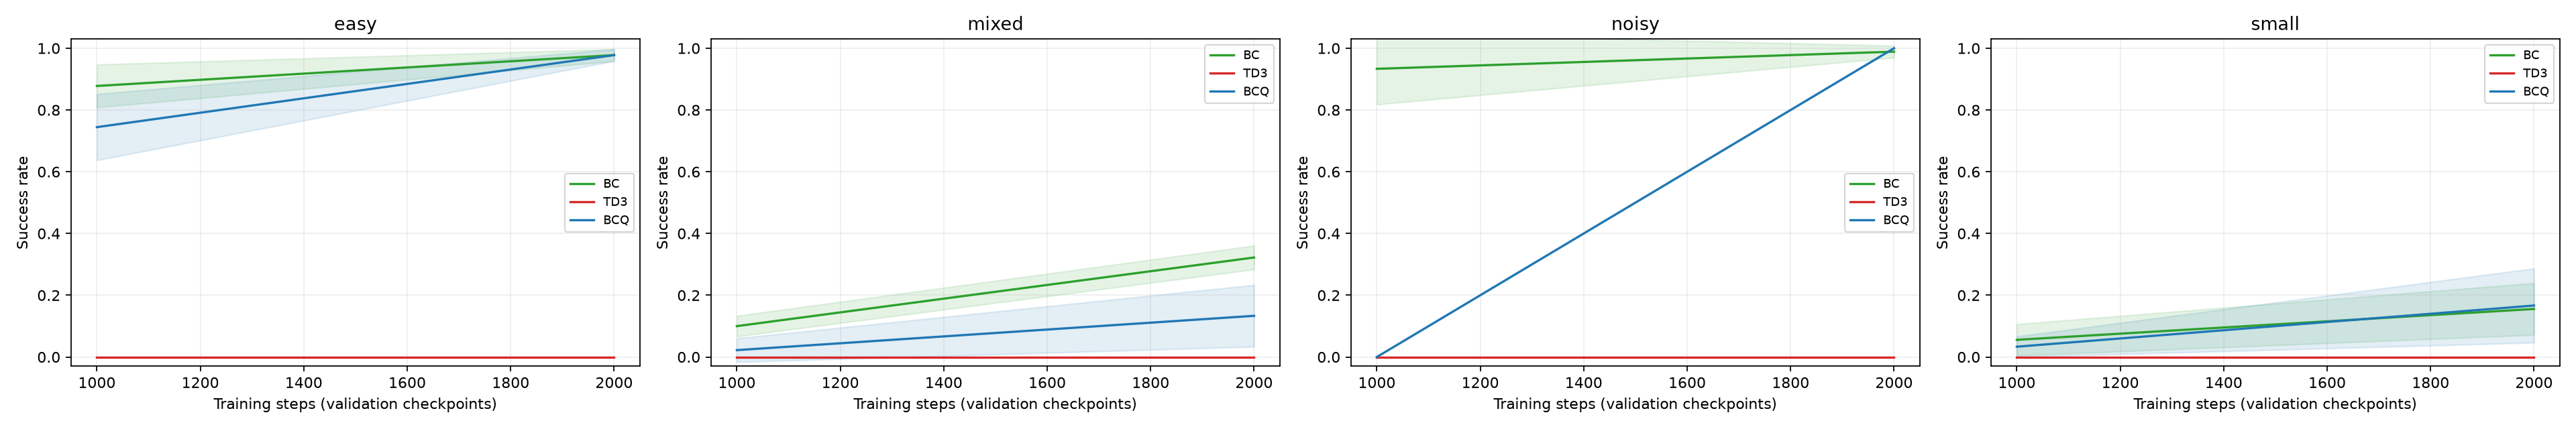

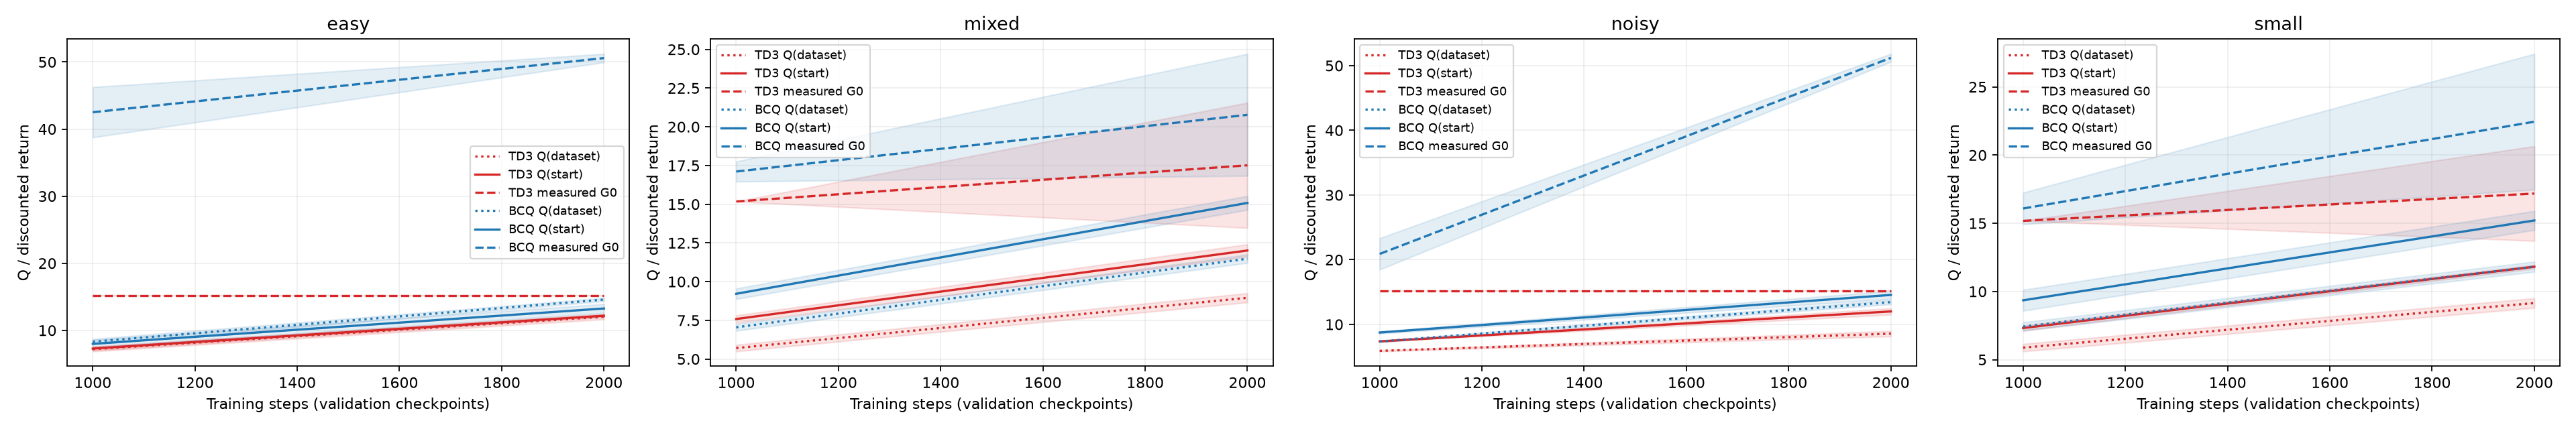

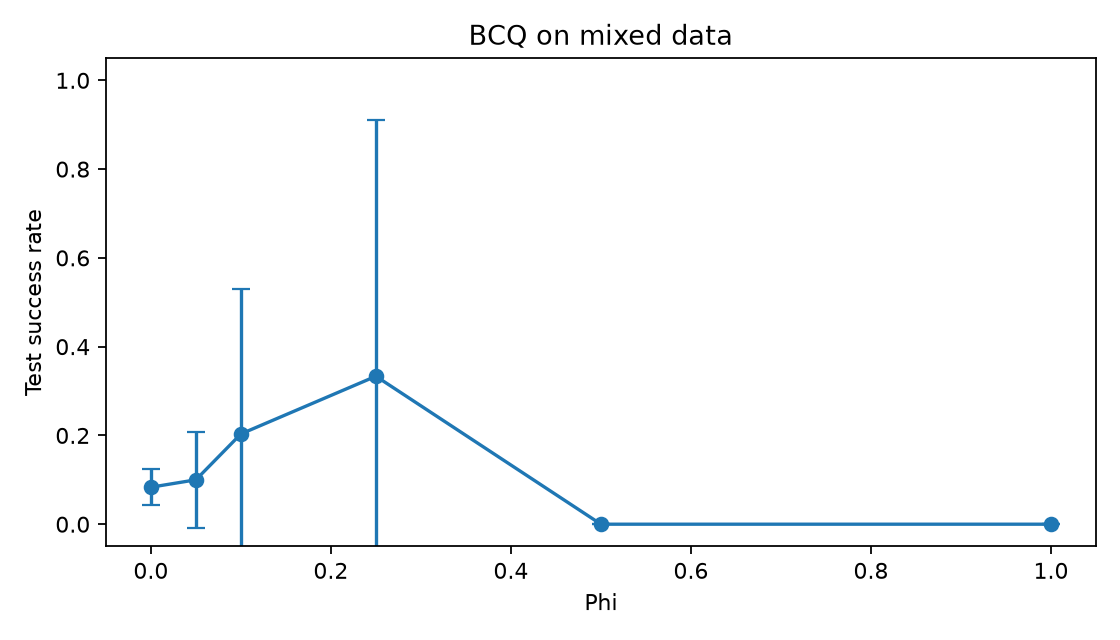

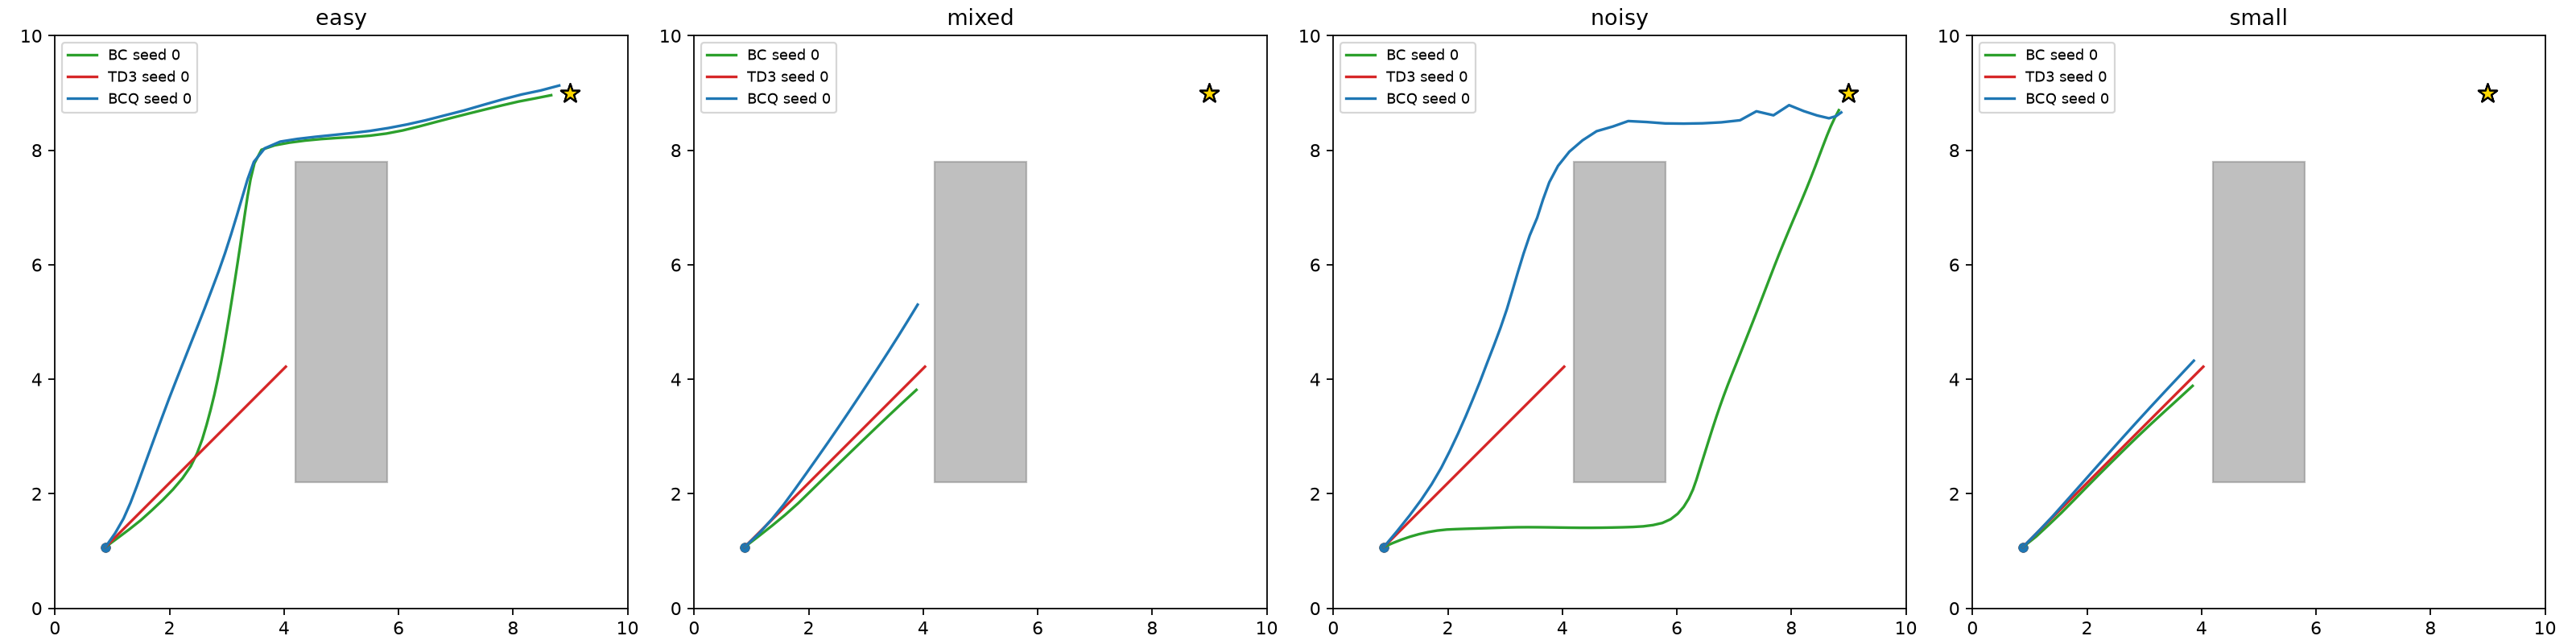

In [9]:
report = Path("results/benchmark/report")
if not (report / "results_table.md").is_file():
    raise FileNotFoundError("Run the benchmark and build its report using the README commands.")

for filename in ("results_table.md", "generalization_table.md", "phi_table.md"):
    display(Markdown((report / filename).read_text(encoding="utf-8")))
for filename in ("success_curves.png", "q_curves.png", "phi_ablation.png", "trajectories.png"):
    display(Image(filename=str(report / filename)))

## Interpretation

Increasing Q alone does not establish policy improvement. Check success, collisions
and measured discounted return. Returns stop at the 120-step horizon, while dataset
timeouts retain Bellman bootstrapping. This can also cause Q/return differences.
Generalization uses new start/goal pairs near the original regions, not new maps.